<a href="https://colab.research.google.com/gist/kartheikiyer/4c0d6f3d46e7c3a7a909a5f60d119b37/grounding_llm_answers.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Grounding LLM answers in sources
### A hands-on tutorial using the Pathfinder astronomy corpus

Large language models write fluent, confident text, but fluency is not evidence. In research, every claim should trace back to a source someone can check. This notebook goes through the three steps of **grounding** a model's answer:

1. **Feed the model context.** Retrieve relevant papers and put them in the prompt with your question.
2. **Make the model attribute.** Ask it to say which source supports each sentence, and to quote the supporting words.
3. **Verify the attributions.** Use code to check that each citation points to a source we actually gave it, that the quote is really in that source, and that the quote actually supports the sentence.

Two further parts go deeper:

4. **Measure and improve retrieval.** Build a rough benchmark, then test whether *query expansion* and *reranking* find better sources.
5. **Grounded extraction with LangExtract.** Use a library that ties every extracted fact to its exact position in the source text.

Our library is the corpus behind [Pathfinder](https://huggingface.co/spaces/kiyer/pathfinder): about 1.16 million astro-ph papers (titles, abstracts, authors) with a vector embedding for every abstract.

**Before you start**
* You need an OpenAI API key. In Colab, click the 🔑 (*Secrets*) icon in the left sidebar, add a secret named `OPENAI_API_KEY`, and allow this notebook to access it. If you skip this, the notebook will prompt you for the key. Running the whole notebook costs well under a dollar; most of that is the Part 4 benchmark.
* The corpus download is about 5 GB and takes a couple of minutes. Start with *Runtime → Run all*, then read along while it runs. Part 4 takes a few more minutes.

## 0. Setup

In [1]:
%pip install -q faiss-cpu rapidfuzz "openai>=1.40" datasets huggingface_hub langextract sentence-transformers

In [2]:
import os
from getpass import getpass

try:  # in Colab, read the key from the Secrets panel
    from google.colab import userdata
    os.environ["OPENAI_API_KEY"] = userdata.get("OPENAI_API_KEY")
except Exception:
    if not os.environ.get("OPENAI_API_KEY"):
        os.environ["OPENAI_API_KEY"] = getpass("OpenAI API key: ")

MODEL = "gpt-5.4-mini"                  # the model that answers our questions
JUDGE_MODEL = "gpt-5.4-mini"            # the model that checks citations in Part 3
EMBED_MODEL = "text-embedding-3-small"  # must match the embeddings stored in the corpus

Everything we send to the model goes through one small helper, `ask`. If you pass it a **JSON schema**, the model is forced to reply with JSON in exactly that shape (OpenAI calls this *structured outputs*), and `ask` returns a Python dict. That will matter in Parts 2 and 3, where code, not a human, has to read the model's reply.

In [3]:
import json
from openai import OpenAI

client = OpenAI()

def ask(prompt, system=None, schema=None, model=MODEL):
    # Send one prompt to the model. With a JSON schema, the reply is parsed into a dict.
    messages = [{"role": "system", "content": system}] if system else []
    messages.append({"role": "user", "content": prompt})
    extra = {}
    if schema:
        extra["response_format"] = {"type": "json_schema",
                                    "json_schema": {"name": "reply", "strict": True, "schema": schema}}
    reply = client.chat.completions.create(model=model, messages=messages, **extra).choices[0].message.content
    return json.loads(reply) if schema else reply

print(ask("In one sentence, what is an astronomical redshift?"))

An astronomical redshift is the increase in the wavelength of light from an object, making its light shift toward the red end of the spectrum, usually because the object is moving away or the universe is expanding.


### Load the Pathfinder corpus

Pathfinder stores two things:
* a **table** of papers (title, abstract, authors, date, ADS bibcode, ...), and
* a **FAISS index** of embeddings. An embedding is a list of 1536 numbers that encodes what an abstract is about. Abstracts on similar topics get nearby vectors.

Row *i* of the table and vector *i* of the index belong to the same paper. To search, we embed the question with the same embedding model and ask FAISS for the nearest vectors.

In [4]:
import faiss
from datasets import load_dataset
from huggingface_hub import snapshot_download

corpus_dir = snapshot_download("kiyer/beacon_corpus", repo_type="dataset", local_dir="pathfinder_corpus")
papers = load_dataset("parquet", data_files=f"{corpus_dir}/corpus/*.parquet", split="train")
index = faiss.read_index(f"{corpus_dir}/astroparse_fp16.faiss", faiss.IO_FLAG_MMAP)
print(f"{papers.num_rows:,} papers, {index.ntotal:,} embedding vectors")

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 44 files:   0%|          | 0/44 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/42 [00:00<?, ?it/s]

Generating train split: 0 examples [00:00, ? examples/s]

1,164,007 papers, 1,164,007 embedding vectors


In [5]:
import html
import re
import numpy as np
import pandas as pd
from IPython.display import HTML, Markdown, display

pd.set_option("display.max_colwidth", None)

def clean(text):
    # ADS abstracts contain HTML entities and tags like <SUB>; turn them into plain text.
    text = html.unescape(re.sub(r"<[^>]+>", "", text or ""))
    return re.sub(r"\s+", " ", text).strip()

def embed(text):
    vector = client.embeddings.create(model=EMBED_MODEL, input=[text]).data[0].embedding
    return np.array(vector, dtype=np.float32)

def search(query, k=8):
    # Return the k papers whose abstracts are closest in meaning to the query.
    _, ids = index.search(embed(query)[None, :], k)
    rows = papers[[int(i) for i in ids[0]]]
    return [{"title": clean(rows["title"][j]),
             "abstract": clean(rows["abstract"][j]),
             "first_author": (rows["authors"][j] or ["?"])[0].split(",")[0],
             "year": rows["date"][j].year,
             "url": f"https://ui.adsabs.harvard.edu/abs/{rows['bibcode'][j]}/abstract"}
            for j in range(len(ids[0]))]

def show_papers(found):
    rows = "".join(f"<tr><td><b>S{n}</b></td><td><a href='{p['url']}' target='_blank'>{html.escape(p['title'])}</a></td>"
                   f"<td>{html.escape(p['first_author'])}</td><td>{p['year']}</td></tr>"
                   for n, p in enumerate(found, 1))
    display(HTML(f"<table><tr><th>id</th><th>title</th><th>first author</th><th>year</th></tr>{rows}</table>"))

show_papers(search("How do supermassive black holes regulate star formation in their host galaxies?", k=3))

id,title,first author,year
S1,Astrophysics: How black holes restrain old galaxies,Sarzi,2016
S2,Black-hole-regulated star formation in massive galaxies,Martín-Navarro,2018
S3,Impact of supermassive black hole growth on star formation,Harrison,2017


## Why bother? An ungrounded answer

First, do what most people do: just ask the model. We ask for **references** in particular, because references are easy to check.

In [6]:
TOPIC = "the surprisingly large number of massive galaxies JWST has found at redshift z > 7"

REFERENCE_SCHEMA = {
    "type": "object", "additionalProperties": False, "required": ["references"],
    "properties": {"references": {"type": "array", "items": {
        "type": "object", "additionalProperties": False,
        "required": ["first_author", "year", "title", "arxiv_id"],
        "properties": {"first_author": {"type": "string"}, "year": {"type": "integer"},
                       "title": {"type": "string"}, "arxiv_id": {"type": "string"}}}}}}

claimed = ask(f"List 5 key papers on {TOPIC}. For each, give the first author's last name, "
              "the year, the title and the arXiv ID.", schema=REFERENCE_SCHEMA)["references"]
pd.DataFrame(claimed)

,first_author,year,title,arxiv_id
0,Labbé,2023,A population of red galaxies at z ~ 9-16 revealed by JWST observations of the early Universe,arXiv:2207.12446
1,Naidu,2022,Rapid emergence of a massive red galaxy population at z ~ 3-7 with JWST,arXiv:2208.02794
2,Grazian,2023,Massive galaxies at z > 7 in the CEERS survey: UV luminosity function and stellar mass function,arXiv:2301.09717
3,Finkelstein,2023,A CEERS candidate massive galaxy at z ~ 8: implications for early galaxy formation,arXiv:2301.05185
4,Harikane,2023,A substantial population of massive galaxies at z > 7 revealed by JWST/NIRCam,arXiv:2208.01612


These look plausible. Do they exist? We check each one two ways:
* ask the **arXiv API** whether that arXiv ID exists, and what its real title is;
* search **Pathfinder** with the claimed title, and report the closest real paper and how similar its title is (100% = identical).

In [7]:
import requests
import xml.etree.ElementTree as ET
from rapidfuzz import fuzz

ARXIV_ID = re.compile(r"\d{4}\.\d{4,5}")

def arxiv_titles(ids):
    # Look up arXiv IDs with the arXiv API. Returns {id: title} for the IDs that exist.
    if not ids:
        return {}
    response = requests.get("https://export.arxiv.org/api/query",
                            params={"id_list": ",".join(ids), "max_results": len(ids)}, timeout=30)
    atom = {"a": "http://www.w3.org/2005/Atom"}
    entries = ET.fromstring(response.text).findall("a:entry", atom)
    return {ARXIV_ID.search(e.find("a:id", atom).text).group(): clean(e.find("a:title", atom).text) for e in entries}

def check_references(refs):
    ids = [m.group() for r in refs if (m := ARXIV_ID.search(r["arxiv_id"]))]
    on_arxiv = arxiv_titles(ids)
    rows = []
    for r in refs:
        m = ARXIV_ID.search(r["arxiv_id"])
        closest = max(search(r["title"], k=10), key=lambda p: fuzz.token_sort_ratio(r["title"].lower(), p["title"].lower()))
        rows.append({"claimed reference": f"{r['first_author']} ({r['year']}): {r['title']}",
                     "claimed arXiv ID": r["arxiv_id"],
                     "what arXiv has at that ID": on_arxiv.get(m.group(), "no such paper") if m else "not a valid ID",
                     "closest real paper (Pathfinder)": f"{closest['first_author']} ({closest['year']}): {closest['title']}",
                     "title match": f"{fuzz.token_sort_ratio(r['title'].lower(), closest['title'].lower()):.0f}%"})
    return pd.DataFrame(rows)

check_references(claimed)

,claimed reference,claimed arXiv ID,what arXiv has at that ID,closest real paper (Pathfinder),title match
0,Labbé (2023): A population of red galaxies at z ~ 9-16 revealed by JWST observations of the early Universe,arXiv:2207.12446,A population of red candidate massive galaxies ~600 Myr after the Big Bang,Austin (2023): A Large Population of Faint 8 < z < 16 Galaxies Found in the First JWST NIRCam Observations of the NGDEEP Survey,64%
1,Naidu (2022): Rapid emergence of a massive red galaxy population at z ~ 3-7 with JWST,arXiv:2208.02794,"Schrodinger's Galaxy Candidate: Puzzlingly Luminous at $z\approx17$, or Dusty/Quenched at $z\approx5$?","Nelson (2022): JWST Reveals a Population of Ultrared, Flattened Galaxies at 2 ≲ z ≲ 6 Previously Missed by HST",60%
2,Grazian (2023): Massive galaxies at z > 7 in the CEERS survey: UV luminosity function and stellar mass function,arXiv:2301.09717,Reconfigurable Intelligent Surface Aided Amplitude- and Phase-Modulated Downlink Transmission,Bhatawdekar (2018): Evolution of the galaxy stellar mass functions and UV luminosity functions at z = 6-9 in the Hubble Frontier Fields,72%
3,Finkelstein (2023): A CEERS candidate massive galaxy at z ~ 8: implications for early galaxy formation,arXiv:2301.05185,Nonuniqueness of trajectories on a set of full measure for Sobolev vector fields,Jin (2022): Massive galaxy formation caught in action at z ∼ 5 with JWST,58%
4,Harikane (2023): A substantial population of massive galaxies at z > 7 revealed by JWST/NIRCam,arXiv:2208.01612,A Comprehensive Study on Galaxies at z~9-16 Found in the Early JWST Data: UV Luminosity Functions and Cosmic Star-Formation History at the Pre-Reionization Epoch,Nilo-Castellón (2025): Faint galaxies in the Zone of Avoidance revealed by JWST/NIRCam,60%


Results vary from run to run, but you will typically see a mix of:
* real papers with the right title and ID,
* real authors attached to **invented titles** (often a near-miss of the real one),
* real titles with the **wrong arXiv ID**, or IDs that don't exist at all.

The model isn't "lying". It generates *plausible* text, and a plausible reference is not the same as a real one. It also gives no hint which of its references are real. Grounding addresses this by giving the model the actual sources and then checking how it used them.

## Part 1: Feed the model context along with your question

This pattern is called **retrieval-augmented generation (RAG)**:
1. **retrieve** documents relevant to the question (here, a Pathfinder search),
2. paste them into the prompt **with labels** (S1, S2, ...) so they can be referred to,
3. instruct the model to answer **only** from them.

Change `QUESTION` to anything you like. The rest of the notebook will follow.

In [8]:
QUESTION = ("What do JWST observations tell us about the abundance of massive galaxies at very high redshift, "
            "and is it in tension with ΛCDM?")

sources = search(QUESTION, k=8)
show_papers(sources)

id,title,first author,year
S1,JWST high redshift galaxy observations have a strong tension with Planck CMB measurements,Wang,2023
S2,No Tension: JWST Galaxies at z > 10 Consistent with Cosmological Simulations,McCaffrey,2023
S3,Matching JWST UV Luminosity Functions with Refined $Λ$CDM Halo Models,Fakhry,2025
S4,Late-time growth weakly affects the significance of high-redshift massive galaxies,Xia,2025
S5,Accelerated formation of ultra-massive galaxies in the first billion years,Xiao,2024
S6,Halo mass functions at high redshift,O'Brennan,2024
S7,Stress testing ΛCDM with high-redshift galaxy candidates,Boylan-Kolchin,2023
S8,Massive dark matter haloes at high redshift: implications for observations in the JWST era,Chen,2023


In [9]:
def format_sources(sources):
    return "\n\n".join(f"[S{n}] {p['title']} ({p['first_author']} {p['year']})\n{p['abstract']}"
                       for n, p in enumerate(sources, 1))

def grounded_prompt(question, sources):
    return f"Sources:\n\n{format_sources(sources)}\n\nQuestion: {question}"

BRIEF = "Answer in one paragraph of at most 150 words."
GROUNDED_SYSTEM = ("You are a careful research assistant. Answer the question using ONLY the sources provided. "
                   "If the sources do not contain the answer, say so instead of guessing. " + BRIEF)

prompt = grounded_prompt(QUESTION, sources)
print(f"The prompt is {len(prompt):,} characters. The first part looks like this:\n")
print(prompt[:1500], "...")

The prompt is 10,714 characters. The first part looks like this:

Sources:

[S1] JWST high redshift galaxy observations have a strong tension with Planck CMB measurements (Wang 2023)
JWST high redshift galaxy observations predict a higher star formation efficiency than the standard cosmology does, which poses a new tension to $\Lambda$CDM. We find that the situation is worse than expected. The true situation is that the Planck CMB measurement has a strong tension with JWST high redshift galaxy observations. Specifically, we make a trial to alleviate this tension by considering alternative cosmological models including dark matter-baryon interaction, $f(R)$ gravity and dynamical dark energy. Within current cosmological constraints from Planck-2018 CMB data, we find that these models all fail to explain such a large tension. A possible scenario to escape from cosmological constraints is the extended Press-Schechter formalism, where we consider the local environmental effect on the early 

Now ask the same question twice, once on its own and once with the sources:

In [10]:
no_context = ask(QUESTION, system=BRIEF)
with_context = ask(grounded_prompt(QUESTION, sources), system=GROUNDED_SYSTEM)

display(Markdown(f"#### Without sources\n{no_context}\n\n#### With sources\n{with_context}"))

#### Without sources
JWST has found a surprisingly large number of bright, apparently massive galaxy candidates at very high redshift (roughly z ≳ 10–15), more than many pre-JWST models expected, which initially raised claims that massive galaxies might be too common that early. However, much of that apparent excess has softened as deeper imaging, better photometric redshifts, spectroscopy, and improved stellar-mass estimates accounted for dust, nebular emission, lensing, and contamination by lower-redshift interlopers. The current picture is that JWST is revealing massive galaxies earlier and perhaps somewhat more efficiently than older models predicted, but there is no clear, robust, order-of-magnitude conflict with ΛCDM. The strongest tension is more about whether galaxy-formation physics in the earliest halos is more efficient than assumed, rather than a direct failure of the cosmological model itself.

#### With sources
JWST observations have revealed an unexpected abundance of massive galaxies at very high redshift, with some studies describing these objects as unusually luminous and massive at \(z \gtrsim 7\) and even \(z \sim 10\!-\!15\) [S3, S4, S7]. Whether this is truly in tension with \(\Lambda\)CDM is not settled in the sources: several papers say there is a strong tension or that the galaxies lie at the edge of standard-model limits [S1, S7], while others find no tension when higher-resolution simulations or additional uncertainties are included [S2, S5, S8]. One study also argues that refined halo modeling within \(\Lambda\)CDM can reproduce the JWST luminosity functions without new physics [S3]. So the observations suggest a surprisingly large abundance of early massive galaxies, but the existence of a true conflict with \(\Lambda\)CDM remains debated.

The two answers may sound equally confident. The second one is *supposed* to use only the eight abstracts, but nothing in it shows which sentence came from which source, or whether some came from the model's memory anyway (to some extent this also depends on the models themselves, especially true when using older or small local models).

Grounding also means being able to say **"the sources don't cover this."** Ask something the retrieved papers don't address:

In [11]:
print(ask(grounded_prompt("What do these papers find about the rotation curves of dwarf galaxies?", sources),
          system=GROUNDED_SYSTEM))

The provided sources do not discuss the rotation curves of dwarf galaxies, so I can’t determine what these papers find about that topic from the evidence given.


## Part 2: Get the model to attribute its claims to the context

### 2a. Inline citations
The simplest form of attribution is to ask for a source tag after every sentence.

In [12]:
CITE_SYSTEM = GROUNDED_SYSTEM + " After every sentence, cite the supporting source(s) in square brackets, e.g. [S2] or [S1, S4]."

display(Markdown(ask(grounded_prompt(QUESTION, sources), system=CITE_SYSTEM)))

JWST observations have revealed an unexpectedly abundant population of massive, and in some cases very luminous, galaxies at very high redshift, with candidates reported around \(z \sim 7\)–15 and even \(z>10\). [S3, S4, S7] Some sources say this appears to be in tension with standard \(\Lambda\)CDM, with the most massive candidates lying near or at the edge of theoretical limits, while others find no tension when using high-resolution simulations or when accounting for modeling uncertainties. [S1, S2, S5, S7, S8] So, the literature provided is mixed: JWST suggests more massive early galaxies than expected, but whether this is a true tension with \(\Lambda\)CDM remains unresolved. [S1, S2, S3, S8]

This is better, but `[S2]` only means the model *claims* S2 supports the sentence. To check that, we need two more things:
* **the exact supporting words.** A quote can be compared with the source character by character.
* **a machine-readable format.** Then code, not a person, can do the checking.

### 2b. Structured citations with quotes
We define a JSON schema: an answer is a list of sentences, and each sentence has a list of citations, each made of a source ID and a verbatim quote. The `description` fields are instructions the model sees.

In [13]:
ANSWER_SCHEMA = {
    "type": "object", "additionalProperties": False, "required": ["sentences"],
    "properties": {"sentences": {"type": "array", "items": {
        "type": "object", "additionalProperties": False, "required": ["text", "citations"],
        "properties": {
            "text": {"type": "string", "description": "one sentence of the answer"},
            "citations": {"type": "array", "items": {
                "type": "object", "additionalProperties": False, "required": ["source", "quote"],
                "properties": {
                    "source": {"type": "string", "description": "source id, e.g. S3"},
                    "quote": {"type": "string", "description": "the supporting passage, copied word for word from that source"},
                }}}}}}}}

QUOTE_SYSTEM = GROUNDED_SYSTEM + (" Write the answer as a list of sentences. For each sentence, give every source that "
                                  "supports it and copy the exact supporting passage from that source, word for word.")

answer = ask(grounded_prompt(QUESTION, sources), system=QUOTE_SYSTEM, schema=ANSWER_SCHEMA)
print(json.dumps(answer, indent=2, ensure_ascii=False)[:1200], "...")

{
  "sentences": [
    {
      "text": "JWST observations have revealed an unexpected abundance of massive galaxies at very high redshift, with some studies describing them as “unexpectedly massive and luminous” or a “bevy of high-redshift galaxy candidates with unexpectedly high stellar masses.”",
      "citations": [
        {
          "source": "S3",
          "quote": "The James Webb Space Telescope (JWST) has unveiled a population of unexpectedly massive and luminous galaxies at redshifts $z \\gtrsim 7$"
        },
        {
          "source": "S7",
          "quote": "Early data from the James Webb Space Telescope (JWST) have revealed a bevy of high-redshift galaxy candidates with unexpectedly high stellar masses."
        },
        {
          "source": "S5",
          "quote": "Recent James Webb Space Telescope (JWST) observations have revealed an unexpected abundance of massive-galaxy candidates in the early Universe"
        }
      ]
    },
    {
      "text": "Several so

In [14]:
def show_answer(answer):
    out = []
    for s in answer["sentences"]:
        tags = "".join(f"<sup>[{html.escape(c['source'])}]</sup>" for c in s["citations"])
        quotes = "".join(f"<div style='margin-left:2em;font-size:90%;opacity:.7'>{html.escape(c['source'])}: "
                         f"&ldquo;{html.escape(c['quote'])}&rdquo;</div>" for c in s["citations"])
        out.append(f"<p style='margin:.8em 0 .2em'>{html.escape(s['text'])} {tags}</p>{quotes}")
    display(HTML("".join(out)))

show_answer(answer)

Each sentence now comes with evidence attached. But so far this is still just the model's say-so: it wrote both the sentences *and* the citations. Next we check them.

## Part 3: Verify the citations

For every citation we ask three questions:

| check | question | how |
|---|---|---|
| **1. The source exists** | Is `S7` one of the sources we actually provided? | a dictionary lookup |
| **2. The quote is real** | Does the quoted passage actually appear in that source? | string matching |
| **3. The quote supports the claim** | Does the passage back up the sentence it's attached to? | a second model call (the "judge") |

Checks 1 and 2 are plain code: deterministic, free, and impossible to talk your way past. Check 3 requires understanding the language, so we use a model, but in a separate call whose only job is judging.

### Check 2: is the quote really in the source?
An exact match is the gold standard. Models sometimes change a character or two (a dash, a Greek letter), so we also accept *close* matches, found with fuzzy matching (`rapidfuzz`). Fuzzy matching is dangerous for numbers, though: "80 pc" vs "50 pc" is a 1-character difference that changes the science. So any close match whose numbers differ is flagged.

In [15]:
def numbers(text):
    return sorted(re.findall(r"\d+(?:\.\d+)?", text))

def find_quote(quote, source_text):
    # Locate a quote in a source. Returns (status, start, end); status is one of
    # 'verbatim', 'close', 'numbers differ' or 'not found'.
    q, s = clean(quote).lower(), source_text.lower()
    if q and q in s:
        start = s.index(q)
        return "verbatim", start, start + len(q)
    match = fuzz.partial_ratio_alignment(q, s)
    if match.score >= 90:
        same_numbers = numbers(q) == numbers(s[match.dest_start:match.dest_end])
        return ("close" if same_numbers else "numbers differ"), match.dest_start, match.dest_end
    return "not found", None, None

abstract = sources[0]["abstract"]
for test in [abstract[:90],                                  # copied exactly
             abstract[:90].replace(" the ", " a ", 1),       # a small wording change
             "these galaxies were detected at 98 percent confidence"]:  # invented
    print(find_quote(test, abstract)[0], "|", test)

verbatim | JWST high redshift galaxy observations predict a higher star formation efficiency than the
verbatim | JWST high redshift galaxy observations predict a higher star formation efficiency than the
not found | these galaxies were detected at 98 percent confidence


### Check 3: does the quote support the sentence?
A quote can be real but still not support the sentence it's attached to: the sentence might overstate it, add a number, or say something the quote never mentions. We ask a **judge** model to compare the evidence with the claim.

Two details matter:
* The judge sees **the source's own words** at the matched location, not the model's version of the quote. A slightly altered quote therefore can't help a claim pass.
* Quotes that failed check 1 or 2 are not passed to the judge at all. A citation we couldn't find doesn't count as evidence.

In [16]:
JUDGE_SYSTEM = (
    "You check citations. Given EVIDENCE quoted from scientific papers and a CLAIM written using it, decide whether "
    "the evidence alone backs the claim. SUPPORTED: every part of the claim is stated or directly implied by the "
    "evidence. PARTIAL: some parts are backed, others are not. UNSUPPORTED: the evidence does not back the claim. "
    "CONTRADICTED: the evidence says the opposite. Be strict about numbers and about how strong the claim is.")

VERDICT_SCHEMA = {
    "type": "object", "additionalProperties": False, "required": ["verdict", "reason"],
    "properties": {"verdict": {"type": "string", "enum": ["SUPPORTED", "PARTIAL", "UNSUPPORTED", "CONTRADICTED"]},
                   "reason": {"type": "string", "description": "one short sentence"}}}

def judge(claim, evidence):
    return ask(f"EVIDENCE:\n{evidence}\n\nCLAIM:\n{claim}", system=JUDGE_SYSTEM, schema=VERDICT_SCHEMA, model=JUDGE_MODEL)

def verify(answer, sources):
    by_id = {f"S{n}": p for n, p in enumerate(sources, 1)}
    report = []
    for sentence in answer["sentences"]:
        citations, evidence = [], []
        for c in sentence["citations"]:
            source = by_id.get(c["source"].strip())                                # check 1
            if source is None:
                citations.append({**c, "match": "no such source", "span": None})
                continue
            status, start, end = find_quote(c["quote"], source["abstract"])       # check 2
            citations.append({**c, "match": status, "span": (start, end)})
            if status in ("verbatim", "close"):
                evidence.append(f"[{c['source']}] {source['abstract'][start:end]}")
        if evidence:                                                               # check 3
            verdict = judge(sentence["text"], "\n".join(evidence))
        else:
            verdict = {"verdict": "UNSUPPORTED", "reason": "no citation that passed checks 1 and 2"}
        report.append({"sentence": sentence["text"], "citations": citations, **verdict})
    return report

In [17]:
COLORS = {"verbatim": "#1a7f37", "close": "#4d7c0f", "numbers differ": "#bc4c00", "not found": "#cf222e",
          "no such source": "#cf222e", "SUPPORTED": "#1a7f37", "PARTIAL": "#9a6700", "UNSUPPORTED": "#cf222e",
          "CONTRADICTED": "#82071e"}

def badge(label):
    return (f"<span style='background:{COLORS[label]};color:white;border-radius:4px;padding:1px 6px;"
            f"font-size:85%;white-space:nowrap'>{label}</span>")

def show_report(report, notes=None):
    head = "<tr>" + ("<th>sabotage</th>" if notes else "") + "<th>sentence</th><th>citations (checks 1-2)</th><th>support (check 3)</th></tr>"
    rows = []
    for i, r in enumerate(report):
        cites = "<br>".join(f"{html.escape(c['source'])} {badge(c['match'])}" for c in r["citations"]) or "none"
        note = f"<td><i>{html.escape(notes[i])}</i></td>" if notes else ""
        rows.append(f"<tr style='vertical-align:top'>{note}<td style='text-align:left'>{html.escape(r['sentence'])}</td>"
                    f"<td style='text-align:left'>{cites}</td><td style='text-align:left'>{badge(r['verdict'])}<br>"
                    f"<span style='font-size:85%;opacity:.8'>{html.escape(r['reason'])}</span></td></tr>")
    supported = sum(r["verdict"] == "SUPPORTED" for r in report)
    display(HTML(f"<p><b>{supported} of {len(report)} sentences fully supported</b></p><table>{head}{''.join(rows)}</table>"))

def show_highlights(report, sources):
    # Show each cited abstract with the passages that were found highlighted.
    spans = {}
    for r in report:
        for c in r["citations"]:
            if c["span"] and c["span"][0] is not None:
                spans.setdefault(c["source"].strip(), []).append((*c["span"], c["match"]))
    for n, p in enumerate(sources, 1):
        sid, text, pos, out = f"S{n}", p["abstract"], 0, []
        if sid not in spans:
            continue
        for start, end, status in sorted(spans[sid]):
            if start < pos:
                continue  # overlaps an earlier highlight
            out.append(html.escape(text[pos:start]))
            out.append(f"<mark style='background:{COLORS[status]}33;color:inherit;"
                       f"border-bottom:2px solid {COLORS[status]}'>{html.escape(text[start:end])}</mark>")
            pos = end
        out.append(html.escape(text[pos:]))
        display(HTML(f"<h4 style='margin-bottom:.2em'>{sid}: <a href='{p['url']}' target='_blank'>{html.escape(p['title'])}</a></h4>"
                     f"<p style='line-height:1.5'>{''.join(out)}</p>"))

### The verification report

In [18]:
report = verify(answer, sources)
show_report(report)

sentence,citations (checks 1-2),support (check 3)
"JWST observations have revealed an unexpected abundance of massive galaxies at very high redshift, with some studies describing them as “unexpectedly massive and luminous” or a “bevy of high-redshift galaxy candidates with unexpectedly high stellar masses.”",S3 verbatimS7 verbatimS5 verbatim,SUPPORTEDThe evidence directly states that JWST revealed an unexpected abundance of massive/high-redshift galaxies and uses the same descriptions quoted in the claim.
"Several sources say this appears to tension with ΛCDM, but others find no tension or say the issue may be explained by modeling uncertainties or refined halo physics.",S1 verbatimS2 verbatimS3 closeS8 close,SUPPORTEDThe evidence includes both statements of tension with ΛCDM and statements of no tension or explanations in terms of modeling/halo physics.
"So, the observations indicate a possible abundance problem at very high redshift, but the sources do not agree that it is definitively in tension with ΛCDM.",S2 verbatimS7 close,"SUPPORTEDThe evidence says there is no tension with ΛCDM in one source and that the issue is unresolved in another, matching the claim that the observations suggest a possible problem but not a definitive tension."


And here is where each quote was found in its source:

In [19]:
show_highlights(report, sources)

### Does the checker actually catch problems?
A checker that approves everything is useless. To test it, we sabotage the model's real answer in five different ways and run the same `verify` on the result. Each row should come out flagged.

In [20]:
def alter_number(text):
    return re.sub(r"\d+", lambda m: str(int(m.group()) * 3 + 1), text, count=1)

good = [(r["sentence"], c) for r in report for c in r["citations"] if c["match"] == "verbatim"]
sentence, cite = good[0]
by_id = {f"S{n}": p for n, p in enumerate(sources, 1)}
wrong_source = next(sid for sid, p in by_id.items() if find_quote(cite["quote"], p["abstract"])[0] == "not found")
numeric = next(((s, c) for s, c in good if re.search(r"\d", c["quote"])), None)

sabotaged = [
    ("cites a source we never gave it",
     {"text": sentence, "citations": [{"source": "S42", "quote": cite["quote"]}]}),
    ("real quote, attributed to the wrong source",
     {"text": sentence, "citations": [{"source": wrong_source, "quote": cite["quote"]}]}),
    ("sentence overstates its quote",
     {"text": sentence.rstrip(".") + ", and every independent study has since confirmed this beyond doubt.",
      "citations": [cite]}),
    ("no citation at all",
     {"text": "Most astronomers now consider this question completely settled.", "citations": []}),
]
if numeric:
    s, c = numeric
    sabotaged.append(("a number in the quote was changed",
                      {"text": s, "citations": [{"source": c["source"], "quote": alter_number(c["quote"])}]}))

broken_report = verify({"sentences": [item for _, item in sabotaged]}, sources)
show_report(broken_report, notes=[label for label, _ in sabotaged])

caught = [r["verdict"] != "SUPPORTED" or any(c["match"] not in ("verbatim", "close") for c in r["citations"])
          for r in broken_report]
print(f"caught {sum(caught)} of {len(caught)} sabotaged sentences")

sabotage,sentence,citations (checks 1-2),support (check 3)
cites a source we never gave it,"JWST observations have revealed an unexpected abundance of massive galaxies at very high redshift, with some studies describing them as “unexpectedly massive and luminous” or a “bevy of high-redshift galaxy candidates with unexpectedly high stellar masses.”",S42 no such source,UNSUPPORTEDno citation that passed checks 1 and 2
"real quote, attributed to the wrong source","JWST observations have revealed an unexpected abundance of massive galaxies at very high redshift, with some studies describing them as “unexpectedly massive and luminous” or a “bevy of high-redshift galaxy candidates with unexpectedly high stellar masses.”",S1 not found,UNSUPPORTEDno citation that passed checks 1 and 2
sentence overstates its quote,"JWST observations have revealed an unexpected abundance of massive galaxies at very high redshift, with some studies describing them as “unexpectedly massive and luminous” or a “bevy of high-redshift galaxy candidates with unexpectedly high stellar masses.”, and every independent study has since confirmed this beyond doubt.",S3 verbatim,"PARTIALThe evidence supports that JWST unveiled unexpectedly massive and luminous galaxies at z ≳ 7, but it does not mention an abundance, the quoted wording from other studies, or that every independent study confirmed it beyond doubt."
no citation at all,Most astronomers now consider this question completely settled.,none,UNSUPPORTEDno citation that passed checks 1 and 2
a number in the quote was changed,"JWST observations have revealed an unexpected abundance of massive galaxies at very high redshift, with some studies describing them as “unexpectedly massive and luminous” or a “bevy of high-redshift galaxy candidates with unexpectedly high stellar masses.”",S3 numbers differ,UNSUPPORTEDno citation that passed checks 1 and 2


caught 5 of 5 sabotaged sentences


### What verification can and cannot tell you

* **Checks 1 and 2 are facts.** If a quote is found verbatim, those words really are in that paper. This is the part to trust most.
* **Check 3 is a model's opinion.** The judge can be wrong too, so spot-check its verdicts, especially PARTIAL ones. It helps that the judge sees only the evidence and the claim, not the question, and is told to be strict.
* **Grounded is not the same as true.** A verified answer faithfully reflects *these eight abstracts*. Abstracts can oversell, papers can be wrong or superseded, and the search can miss the most important paper. The honest summary is "these sources say X," not "X is true."
* **Fuzzy matching has blind spots.** Inserting "not" into a long quote still scores above 90%. That's why the judge reads the source's words rather than the quote, and why the report shows *close* and *verbatim* separately.

## Part 4: How good is the retrieval, and can we make it better?

Everything above depends on step 1. If the most relevant paper isn't among the 8 we retrieve, the model can't cite it, and the checks in Part 3 can't notice it's missing. They only check what the model *did* cite. So in this part we measure retrieval, then try two standard ways to improve it:

* **Query expansion:** rewrite the question before searching, so it looks more like the abstracts we're searching.
* **Reranking:** fetch a larger pool of candidates with the fast embedding search, then re-order the pool with a slower, more careful model.

Whether these help is an empirical question, so we first need a benchmark.

### 4a. A rough benchmark: known-item search
Collecting real relevance judgments is expensive. A cheap stand-in is to pick random papers, have a model write the question each paper answers (in its own words), and check whether search finds the original paper. We measure:
* **hit@k**: the fraction of questions whose source paper is in the top *k* results. **hit@8** asks: would this paper have made it into our prompt?
* **MRR** (mean reciprocal rank): the average of 1/rank. That's 1 if the paper comes first, 0.5 if second, and so on, and 0 if it's not in the top 100.

It's a rough benchmark. Other papers may answer a question just as well, so the scores underestimate how useful the results are. With 50 questions, each hit@k number is uncertain by about ±0.07.

In [21]:
N_BENCH = 50
QUESTION_WRITER = (
    "You write test questions for a literature search engine. Given a paper's title and abstract, write ONE question "
    "that a researcher might type when looking for the main result of this paper, before knowing the paper exists. "
    "Ask about the science, not the paper. Use your own words: do not copy distinctive phrases, and do not mention "
    "the names of specific surveys, instruments, simulations or objects that appear in the abstract.")

def fetch(ids, columns=("title", "abstract")):
    rows = papers.select_columns(list(columns))[ids]
    return [{c: clean(rows[c][j]) for c in columns} for j in range(len(ids))]

# random papers from 2000 onwards with a real abstract
rng = np.random.default_rng(42)
candidates = [int(i) for i in rng.choice(papers.num_rows, size=4 * N_BENCH, replace=False)]
meta = papers.select_columns(["abstract", "date"])[candidates]
bench_ids = [i for i, a, d in zip(candidates, meta["abstract"], meta["date"])
             if len(clean(a)) > 600 and d.year >= 2000][:N_BENCH]

from concurrent.futures import ThreadPoolExecutor

def parallel(fn, *lists):
    # Run API calls 8 at a time instead of one by one.
    with ThreadPoolExecutor(8) as pool:
        return list(pool.map(fn, *lists))

bench_papers = fetch(bench_ids)
questions = parallel(lambda p: ask(f"Title: {p['title']}\n\nAbstract: {p['abstract']}", system=QUESTION_WRITER),
                     bench_papers)
pd.DataFrame({"question": questions, "written from": [p["title"] for p in bench_papers]}).head(5)

,question,written from
0,"Do coronal holes that appear during solar maximum produce slower solar wind than the long-lived polar coronal holes, and do they differ much in temperature or magnetic field strength?",Interplanetary and solar surface properties of coronal holes observed during solar maximum
1,"How can repeated high-resolution radio imaging help us understand the structure and motion of jets in southern active galactic nuclei, and how this relates to their gamma-ray emission?",TANAMI - Tracking Active Galactic Nuclei with Austral Milliarcsecond Interferometry
2,"How do sudden spin-up events in young pulsars vary in size and recovery behavior, and are their amplitudes related to pulsar age or spin-down rate?",29 glitches detected at Urumqi Observatory
3,"How does a strong collisionless shock develop and evolve in counterstreaming laser-generated plasmas, and how thin is the shock compared with the ion mean free path?",Time Evolution of Collisionless Shock in Counterstreaming Laser-Produced Plasmas
4,"How do spectral line profiles in a symbiotic star change over time during a brightening event, and what do those changes reveal about the evolution and slowing of its outflow or jet?",Optical spectroscopic observations of a symbiotic star MWC 560 in the mass accumulation phase


In [22]:
def embed_many(texts):
    data = client.embeddings.create(model=EMBED_MODEL, input=texts).data
    return np.array([d.embedding for d in data], dtype=np.float32)

def nearest(vectors, k=100):
    # Row ids of the k nearest papers, for each vector.
    _, ids = index.search(vectors, k)
    return [[int(i) for i in row] for row in ids]

def evaluate(rankings):
    ranks = [r.index(target) + 1 if target in r[:100] else None for r, target in zip(rankings, bench_ids)]
    hit = lambda k: np.mean([x is not None and x <= k for x in ranks])
    return {"hit@1": hit(1), "hit@8": hit(8), "hit@30": hit(30), "MRR": np.mean([1 / x if x else 0 for x in ranks])}

results = {}
question_vectors = embed_many(questions)
results["embedding search (baseline)"] = nearest(question_vectors)
pd.DataFrame({name: evaluate(r) for name, r in results.items()}).T.round(2)

,hit@1,hit@8,hit@30,MRR
embedding search (baseline),0.48,0.74,0.86,0.57


### 4b. Query expansion
A question and an abstract are different kinds of text, which limits how well a question's embedding matches an abstract's. We try two ways to close the gap:

* **Multi-query:** ask the model for 3 rewordings of the question using the vocabulary abstracts use, search with all four, and merge the result lists with **reciprocal rank fusion (RRF)**. RRF gives each paper a score of Σ 1/(60 + rank) over the lists and sorts by it.
* **HyDE** ("hypothetical document embeddings"): ask the model to *write a fake abstract* that would answer the question, and search with that. The fake abstract doesn't need to be correct. It only needs to *look like* the right abstract.

In [23]:
REWRITE_SCHEMA = {"type": "object", "additionalProperties": False, "required": ["queries"],
                  "properties": {"queries": {"type": "array", "items": {"type": "string"}}}}

def rrf(rankings, k=60):
    score = {}
    for ranking in rankings:
        for rank, doc in enumerate(ranking, 1):
            score[doc] = score.get(doc, 0) + 1 / (k + rank)
    return sorted(score, key=score.get, reverse=True)

def multi_query(question):
    rewrites = ask(f"Question: {question}", schema=REWRITE_SCHEMA, system=(
        "Rewrite this literature-search question as 3 different search queries that use the terminology a paper "
        "abstract might use (synonyms, technical terms, related concepts)."))["queries"][:3]
    return rrf(nearest(embed_many([question] + rewrites)))

def fake_abstract(question):
    return ask(f"Question: {question}", system=(
        "Write a plausible, concise astronomy paper abstract (about 150 words) that would answer this question. "
        "It does not need to be factually correct; it is only used for search."))

def hyde(question):
    return nearest(embed_many([fake_abstract(question)]))[0]

print("QUESTION:", questions[0], "\n\nFAKE ABSTRACT:", fake_abstract(questions[0]))

QUESTION: Do coronal holes that appear during solar maximum produce slower solar wind than the long-lived polar coronal holes, and do they differ much in temperature or magnetic field strength? 

FAKE ABSTRACT: We compare the solar wind associated with transient coronal holes that emerge during solar maximum with the wind from long-lived polar coronal holes. Using EUV imaging, in situ plasma measurements, and magnetic field extrapolations, we find that maximum-phase coronal holes generally produce slower and more variable high-speed streams than the persistent polar holes. While both hole types launch wind with similar large-scale open-flux topology, the maximum-phase sources are typically rooted in more fragmented and mixed-polarity photospheric fields, leading to weaker acceleration and reduced terminal speeds. In contrast, polar coronal holes sustain more stable, faster outflows. We also find only modest differences in coronal temperature between the two populations: both are charac

In [24]:
results["+ multi-query (RRF)"] = parallel(multi_query, questions)
results["+ HyDE"] = parallel(hyde, questions)
pd.DataFrame({name: evaluate(r) for name, r in results.items()}).T.round(2)

,hit@1,hit@8,hit@30,MRR
embedding search (baseline),0.48,0.74,0.86,0.57
+ multi-query (RRF),0.20,0.76,0.82,0.38
+ HyDE,0.40,0.72,0.84,0.54


### 4c. Reranking
Embedding search compares two separately computed vectors, so it never looks at the question and the paper together. A **reranker** does: it reads each (question, paper) pair and scores it. That's too slow for 1.16 million papers but fine for a pool of 30. We compare three:

* **Pathfinder's keyword boost**, as in the Pathfinder app: take the top 1000 by embedding, then multiply each similarity by a weight that counts how often the question's nouns and adjectives appear in the paper's stored keywords.
* **A cross-encoder:** a small open model (22M parameters, trained on web-search data) that scores pairs. It runs locally, no API needed.
* **An LLM reranker:** show the model the question and the 30 candidates, and ask it to score each one from 0 to 3.

In [25]:
import spacy
from sentence_transformers import CrossEncoder

POOL = 30  # rerank the top 30 candidates

try:
    nlp = spacy.load("en_core_web_sm")
except OSError:
    spacy.cli.download("en_core_web_sm")
    nlp = spacy.load("en_core_web_sm")
keywords_column = papers.select_columns(["keywords"])

def pathfinder_rerank(question, vector):
    # Pathfinder's ranking: embedding similarity x keyword-overlap weight, over the top 1000.
    distances, ids = index.search(vector[None, :], 1000)
    similarity = 1 / (distances[0] + 1e-10)
    query_words = [t.text for t in nlp(question.lower())
                   if t.pos_ in {"PROPN", "ADJ", "NOUN"} and not t.is_stop and not t.is_punct]
    weight = np.full(len(ids[0]), 0.1)
    for j, paper_keywords in enumerate(keywords_column[[int(i) for i in ids[0]]]["keywords"]):
        weight[j] += 0.1 * sum(w in k.lower() for w in query_words for k in paper_keywords or [])
    combined = similarity / similarity.max() * weight / weight.max()
    return [int(ids[0][j]) for j in np.argsort(-combined, kind="stable")]

cross_encoder = CrossEncoder("cross-encoder/ms-marco-MiniLM-L-6-v2")

def cross_encoder_rerank(question, ranking):
    pool = ranking[:POOL]
    scores = cross_encoder.predict([(question, f"{p['title']}. {p['abstract'][:700]}") for p in fetch(pool)])
    return [pool[j] for j in np.argsort(-scores, kind="stable")] + ranking[POOL:]

SCORES_SCHEMA = {"type": "object", "additionalProperties": False, "required": ["scores"],
                 "properties": {"scores": {"type": "array", "items": {
                     "type": "object", "additionalProperties": False, "required": ["paper", "score"],
                     "properties": {"paper": {"type": "integer"}, "score": {"type": "integer"}}}}}}
RERANK_SYSTEM = ("You rank search results. For each numbered paper, score how directly it answers the question: "
                 "3 = directly answers it, 2 = closely related, 1 = same topic, 0 = unrelated. Score every paper.")

def llm_rerank(question, ranking):
    pool = ranking[:POOL]
    listing = "\n\n".join(f"[{n}] {p['title']}. {p['abstract'][:500]}" for n, p in enumerate(fetch(pool)))
    reply = ask(f"Question: {question}\n\nPapers:\n\n{listing}", system=RERANK_SYSTEM, schema=SCORES_SCHEMA)
    score = {s["paper"]: s["score"] for s in reply["scores"]}
    order = sorted(range(len(pool)), key=lambda n: -score.get(n, 0))  # ties keep the embedding order
    return [pool[n] for n in order] + ranking[POOL:]

config.json:   0%|          | 0.00/794 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/1.33k [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/132 [00:00<?, ?B/s]

In [26]:
baseline = results["embedding search (baseline)"]
results["rerank: Pathfinder keyword boost"] = [pathfinder_rerank(q, v) for q, v in zip(questions, question_vectors)]
results["rerank: cross-encoder"] = [cross_encoder_rerank(q, r) for q, r in zip(questions, baseline)]
results["rerank: LLM"] = parallel(llm_rerank, questions, baseline)
# expansion widens the pool, reranking orders it, so try them together
results["HyDE + cross-encoder"] = [cross_encoder_rerank(q, r) for q, r in zip(questions, results["+ HyDE"])]
results["HyDE + LLM rerank"] = parallel(llm_rerank, questions, results["+ HyDE"])
scores = pd.DataFrame({name: evaluate(r) for name, r in results.items()}).T
scores.round(2)

,hit@1,hit@8,hit@30,MRR
embedding search (baseline),0.48,0.74,0.86,0.57
+ multi-query (RRF),0.20,0.76,0.82,0.38
+ HyDE,0.40,0.72,0.84,0.54
rerank: Pathfinder keyword boost,0.12,0.36,0.52,0.21
rerank: cross-encoder,0.40,0.70,0.86,0.53
rerank: LLM,0.56,0.84,0.86,0.66
HyDE + cross-encoder,0.42,0.70,0.84,0.53
HyDE + LLM rerank,0.50,0.78,0.84,0.62


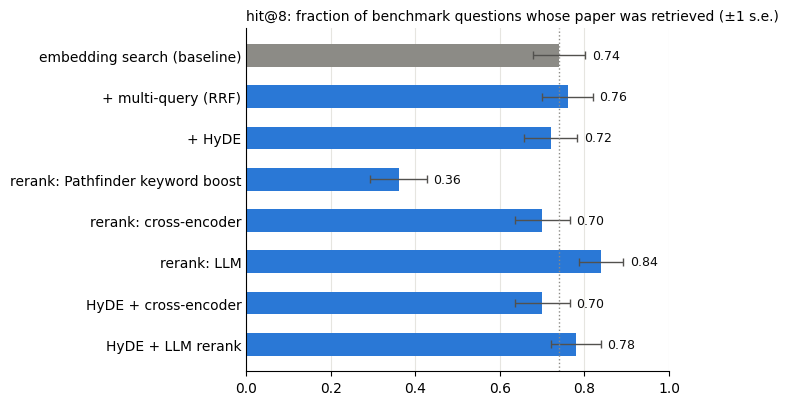

In [27]:
import matplotlib.pyplot as plt

def plot_scores(scores, metric="hit@8"):
    se = np.sqrt(scores[metric] * (1 - scores[metric]) / N_BENCH)  # binomial standard error
    names = list(scores.index)[::-1]
    fig, ax = plt.subplots(figsize=(7, 0.42 * len(names) + 0.8))
    colors = ["#8c8b86" if "baseline" in n else "#2a78d6" for n in names]
    ax.barh(names, scores[metric][names], height=0.55, color=colors,
            xerr=se[names], error_kw={"ecolor": "#52514e", "elinewidth": 1, "capsize": 3})
    for y, n in enumerate(names):
        ax.text(scores[metric][n] + se[n] + 0.015, y, f"{scores[metric][n]:.2f}", va="center", fontsize=9, color="#0b0b0b")
    ax.axvline(scores[metric][names[-1]], color="#8c8b86", lw=1, ls=":")  # baseline level
    ax.set_xlim(0, 1)
    ax.set_title(f"{metric}: fraction of benchmark questions whose paper was retrieved (±1 s.e.)", fontsize=10, loc="left")
    ax.spines[["top", "right"]].set_visible(False)
    ax.tick_params(axis="y", length=0)
    ax.grid(axis="x", color="#e6e5e0", lw=0.8)
    ax.set_axisbelow(True)
    plt.tight_layout()
    plt.show()

plot_scores(scores, "hit@8")

How to read the results (your numbers will differ a little from run to run). When we tested this notebook:

* **The LLM reranker helped the most, every time**, raising `hit@1` and MRR well above the baseline. It reads the question and each candidate together, which embeddings never do.
* **Query expansion was mixed.** HyDE and multi-query were sometimes a bit better, sometimes a bit worse, usually within the error bars. Expansion helps most when questions and abstracts use different vocabulary, and the questions here were written from the abstracts.
* **The small cross-encoder was mixed too.** It was trained on web-search queries, not astronomy, which is a reminder that an off-the-shelf model can fail to transfer to a new domain.
* **The keyword boost did much *worse* than plain embedding search.** Its keyword weight varies a lot from paper to paper and swamps the similarity score. "Improvements" need to be measured.
* **A reranker can't rescue a paper that isn't in its pool**, so `hit@30` of the first stage is its ceiling.
* **Caveats.** The questions were written by a model that read the target abstract, and the LLM reranker is the same model, so it may find these questions unusually easy. There's one "right" paper per question, and 50 questions is a small sample. Treat differences smaller than the error bars as noise.

### 4d. Plugging the better retriever into the grounding pipeline
Retrieval is just the first step of Parts 1–3, so an improved retriever drops straight in. Here we use HyDE to build the pool, the LLM to rerank it, and keep the top 8:

In [28]:
def better_search(question, k=8):
    ranking = llm_rerank(question, hyde(question))[:k]
    return [{**p, "first_author": (r["authors"] or ["?"])[0].split(",")[0], "year": r["date"].year,
             "url": f"https://ui.adsabs.harvard.edu/abs/{r['bibcode']}/abstract"}
            for p, r in zip(fetch(ranking), (papers[i] for i in ranking))]

better_sources = better_search(QUESTION)
old_titles = {p["title"] for p in sources}
print("New sources not found by plain embedding search:")
for p in better_sources:
    if p["title"] not in old_titles:
        print(f"  + {p['first_author']} {p['year']}: {p['title']}")
better_answer = ask(grounded_prompt(QUESTION, better_sources), system=QUOTE_SYSTEM, schema=ANSWER_SCHEMA)
show_report(verify(better_answer, better_sources))

New sources not found by plain embedding search:
  + Wang 2025: JWST/MIRI Reveals the True Number Density of Massive Galaxies in the Early Universe
  + Gottumukkala 2024: Unveiling the hidden Universe with JWST: the contribution of dust-obscured galaxies to the stellar mass function at z 3 - 8
  + Xiao 2023: Massive Optically Dark Galaxies Unveiled by JWST Challenge Galaxy Formation Models
  + Haslbauer 2022: Has JWST Already Falsified Dark-matter-driven Galaxy Formation?
  + Wang 2024: The true number density of massive galaxies in the early Universe revealed by JWST/MIRI
  + Williams 2024: The Galaxies Missed by Hubble and ALMA: The Contribution of Extremely Red Galaxies to the Cosmic Census at 3 < z < 8


sentence,citations (checks 1-2),support (check 3)
"JWST observations initially suggested an unexpected abundance of massive galaxies at very high redshift, with the observed number density and maximum stellar mass appearing higher than model predictions.",S7 verbatimS1 verbatim,SUPPORTEDThe evidence states that early JWST studies found an unexpected abundance of massive galaxies at z~5–8 and that observed number density and maximum stellar mass appeared higher than model predictions.
"The sources say this can create tension with ΛCDM, but they also show that improved JWST/MIRI measurements reduce the inferred abundance and the tension is not necessarily decisive.",S7 verbatimS1 verbatimS7 close,"SUPPORTEDThe evidence says the observed abundance/mass may pose a serious problem to ΛCDM, and that MIRI reduces inferred number densities, which can lessen the tension."
"So, JWST data indicate a possible or moderate tension with ΛCDM from early claims, but later analyses with better near-infrared/MIRI constraints reduce the discrepancy rather than proving that ΛCDM is ruled out.",S1 verbatimS6 verbatim,"UNSUPPORTEDThe evidence only says results within ΛCDM show a moderate efficiency increase and stresses uncertainty modeling; it does not mention JWST, early claims, or any tension being reduced."


## Part 5: Grounded extraction with LangExtract

In Parts 2 and 3 we asked for quotes and wrote our own code to find them in the sources. [LangExtract](https://github.com/google/langextract) is an open-source library from Google that builds this in. You describe what to extract and give one worked example. It then:

1. asks the model for extractions, each of which must be text copied from the source,
2. **aligns** every extraction to exact character positions in the source, and labels how well it matched (`MATCH_EXACT`, `MATCH_FUZZY`, `MATCH_LESSER`, or not found),
3. draws an interactive view with each extraction highlighted in the original text.

This is "grounding" in the strictest sense: every fact is tied to a location you can point to. Let's extract the samples, methods, measurements and conclusions from our 8 sources.

In [29]:
import langextract as lx

EXTRACTION_PROMPT = (
    "Extract the sample, methods, measurements and conclusions from this astronomy abstract. Use the exact text of "
    "the abstract for every extraction (no paraphrasing) and do not overlap extractions. "
    "Add attributes that would be useful in a table.")

# one worked example teaches the model the format and the kind of attributes we want
EXTRACTION_EXAMPLES = [lx.data.ExampleData(
    text=("We measure the dynamical masses of 12 quiescent galaxies at 2 < z < 3 using deep Keck/MOSFIRE spectroscopy. "
          "Their median velocity dispersion is 250 km/s, and their dynamical masses agree with their stellar masses. "
          "We conclude that these galaxies were already dynamically mature 2 Gyr after the Big Bang."),
    extractions=[
        lx.data.Extraction(extraction_class="sample", extraction_text="12 quiescent galaxies at 2 < z < 3",
                           attributes={"size": "12", "redshift": "2 < z < 3"}),
        lx.data.Extraction(extraction_class="method", extraction_text="deep Keck/MOSFIRE spectroscopy",
                           attributes={"type": "spectroscopy"}),
        lx.data.Extraction(extraction_class="measurement", extraction_text="median velocity dispersion is 250 km/s",
                           attributes={"quantity": "velocity dispersion", "value": "250", "unit": "km/s"}),
        lx.data.Extraction(extraction_class="conclusion",
                           extraction_text="these galaxies were already dynamically mature 2 Gyr after the Big Bang",
                           attributes={"topic": "galaxy dynamics"}),
    ])]

documents = [lx.data.Document(text=p["abstract"], document_id=f"S{n}") for n, p in enumerate(sources, 1)]
extracted = list(lx.extract(text_or_documents=documents, prompt_description=EXTRACTION_PROMPT,
                            examples=EXTRACTION_EXAMPLES, model_id=MODEL, api_key=os.environ["OPENAI_API_KEY"],
                            fence_output=True, use_schema_constraints=False, max_workers=8, show_progress=False))
print(sum(len(d.extractions) for d in extracted), "extractions from", len(extracted), "abstracts")

58 extractions from 8 abstracts


LangExtract's viewer for one abstract (use the controls to step through the extractions; change `"S1"` to look at another source):

In [30]:
def show_extractions(source_id):
    doc = next(d for d in extracted if d.document_id == source_id)
    view = lx.visualize(doc)
    display(HTML(view) if isinstance(view, str) else view)

show_extractions("S1")

### Check LangExtract's grounding, too
Each extraction carries a `char_interval` (start and end positions in the source) and an `alignment_status`. Same principle as Part 3: don't trust the tool's labels, check them. Below, for every extraction we cut out the source text at the reported position and compare it with the extracted text, and we also run Part 3's `find_quote` on it.

In [31]:
rows = []
for doc in extracted:
    for e in doc.extractions:
        span = doc.text[e.char_interval.start_pos:e.char_interval.end_pos] if e.char_interval else ""
        rows.append({"source": doc.document_id, "class": e.extraction_class, "extraction": e.extraction_text,
                     "attributes": e.attributes, "alignment": e.alignment_status.name if e.alignment_status else "NONE",
                     "text at that position": span, "position matches": span.lower() == e.extraction_text.lower(),
                     "find_quote": find_quote(e.extraction_text, doc.text)[0]})
extractions = pd.DataFrame(rows)
display(pd.crosstab(extractions["alignment"], extractions["find_quote"], margins=True))
extractions[~extractions["position matches"]][["source", "extraction", "alignment", "find_quote", "text at that position"]]

find_quote,close,verbatim,All
alignment,,,
MATCH_EXACT,0,43,43
MATCH_FUZZY,0,12,12
MATCH_LESSER,1,2,3
All,1,57,58


,source,extraction,alignment,find_quote,text at that position
39,S7,the most massive galaxy candidates in JWST observations at z ≈ 7-10,MATCH_LESSER,verbatim,the
43,S8,the observed ρ*(>M*) at z ~ 7-10,MATCH_LESSER,verbatim,The
46,S8,the combined effect can boost the density by more than one order of magnitude,MATCH_LESSER,close,the


Most extractions are `MATCH_EXACT`. (LangExtract ignores capitalisation, so "The" and "the" count as exact.) The table above lists every extraction whose reported position does *not* hold its text. Typical cases:
* **`MATCH_LESSER` / `MATCH_FUZZY`:** only part of the extraction could be lined up. The "text at that position" can be a much shorter fragment, sometimes just one word. Interestingly, `find_quote` may still report the text as `verbatim`: the words *are* in the abstract, but LangExtract's position points somewhere else.
* **`NONE`:** the model paraphrased despite the instructions, and the text couldn't be located at all. The extraction has no position and shouldn't be cited.

Filter on the alignment status before trusting a position. The same principle applies as in Part 3: the tool's own label is a claim, and checking it is cheap.

### A grounded literature table
Because every extraction is a located span, we can build a table that answers "what does each paper conclude?" where every cell can be traced to exact characters in a specific paper:

In [32]:
conclusions = extractions[(extractions["class"] == "conclusion") & (extractions["alignment"] == "MATCH_EXACT")]
by_source = {f"S{n}": p for n, p in enumerate(sources, 1)}
conclusions.assign(paper=[f"{by_source[s]['first_author']} {by_source[s]['year']}" for s in conclusions["source"]])[
    ["source", "paper", "extraction"]].rename(columns={"extraction": "conclusion (verbatim)"})

,source,paper,conclusion (verbatim)
0,S1,Wang 2023,the situation is worse than expected
1,S1,Wang 2023,the Planck CMB measurement has a strong tension with JWST high redshift galaxy observations
10,S2,McCaffrey 2023,"there are concerns that these observations are in tension with the $\Lambda$CDM model of the universe, as the stellar masses of the galaxies are relatively high for their respective redshifts."
15,S2,McCaffrey 2023,"Within this galaxy formation paradigm, we find excellent agreement with JADES and CEERS."
16,S2,McCaffrey 2023,We find no tension between the $\Lambda$CDM model and current JWST measurements.
17,S2,McCaffrey 2023,"As JWST continues to explore the high redshift universe, high resolution simulations, such as Renaissance, will continue to be crucial in understanding the formation history of early embryonic galaxies."
21,S3,Fakhry 2025,"The James Webb Space Telescope (JWST) has unveiled a population of unexpectedly massive and luminous galaxies at redshifts $z \gtrsim 7$, posing a significant challenge to the standard $Λ$CDM cosmological paradigm."
25,S3,Fakhry 2025,"Our results suggest that the JWST overabundance problem stems not from new physics beyond $Λ$CDM, but from oversimplified treatments of gravitational collapse, highlighting the critical role of small-scale dissipative dynamics in early structure formation."
26,S4,Xia 2025,"the late-time growth rate of structure affects the statistical significance of high-redshift, high-mass objects very weakly"
27,S4,Xia 2025,"if the existence and abundance of these objects are confirmed to be unexpected, the variations in the late-time growth history are unlikely to explain these anomalies"


**How does this compare to Parts 2–3?**
* LangExtract handles **check 2** for you, at scale and with positions. You still have to read the alignment statuses.
* It does *not* do **check 3**. The extracted text is real, but the `attributes` (like `topic` or `unit`) are the model's interpretation and aren't grounded. Whether a conclusion actually answers *your* question is still a judgment call.
* "Extract first, then answer from the extractions" is a useful design for grounded systems: the model can only cite spans that are already known to exist.

## Wrap-up

| step | what we did | what can still go wrong |
|---|---|---|
| 1. context | retrieve papers, put them in the prompt with IDs | the best paper isn't retrieved (Part 4 measures this) |
| 2. attribution | sentences + source IDs + verbatim quotes, as JSON | the model cites, but cites badly |
| 3. verification | source exists, quote is real, quote supports claim | the judge is a model too; grounded ≠ true |

### Try it yourself
1. Change `QUESTION` (Part 1) to a topic in your own research area and re-run from there.
2. Ask a question the retrieved papers can't answer. Does the model admit it? What does the report show?
3. Delete the word "ONLY" from `GROUNDED_SYSTEM`. Do more sentences become unsupported?
4. Retrieve `k=3` or `k=20` sources. How do the answer and the report change?
5. Set `MODEL = "gpt-4o-mini"` (an older, smaller model) and compare how often its quotes are verbatim.
6. The judge uses the same model that wrote the answer. Why might a *different* `JUDGE_MODEL` be a good idea?
7. Part 4: change `POOL` to 10 or 100. How do the rerankers' scores change, and why can't `hit@30` get any better?
8. Part 4: change `QUESTION_WRITER` so the questions are vaguer (like a student's first question on a topic). Which methods hold up?
9. Part 5: add an extraction class of your own (e.g. `"open question"` or `"assumption"`) to the prompt and the example.

### Going further
* [Pathfinder](https://huggingface.co/spaces/kiyer/pathfinder) is a full research assistant built on this corpus. It adds consensus scoring and different answer styles.
* Some LLM APIs now have built-in citation features that return the exact source spans used. They make step 2 easier, but steps 1 and 3 still apply: you choose the sources, and you still check the result.